# 09 - Features v2: team matchup after 30 turns (experiment 06)

The error analysis (`08_error_analysis.ipynb`, experiment 05) showed a calibrated model whose errors are
mostly in battles still open at turn 30. Among the confident errors, the "comebacks" had slightly more
special-attack boosts and better type coverage for the side that came back. The current features only
describe the **two active Pokémon** at turn 30 and a raw team coverage.

This notebook adds the group `team_matchup` (`src/features.py`, `team_matchup_features`). For every battle
it builds a small roster of the Pokémon **still in play** on each side and lets every Pokémon of one side
attack every Pokémon of the other:

| Source | What is used |
|---|---|
| this battle's 30 turns | last HP and status of every Pokémon seen, damaging moves revealed (type and category), boosts of the active Pokémon at turn 30, healing moves revealed, voluntary switches |
| P1 team details | base stats and types of all six P1 Pokémon (also the ones never sent out) |
| species table (train only) | base stats and types of P2's revealed Pokémon (mean stats for unknown species) |
| type chart | type effectiveness |

P2's "alive" set is: not fainted **and** not vanished with HP ≤ 0.5 (the same estimate as `lost_est`), so the
features do not change if P2's KOs were recorded differently on the final evaluation set.

| Sub-group | Features (per side, plus `diff_tm_*`) |
|---|---|
| `tm_types_damage` | `cover` mean best effectiveness against each opponent; `n_se_targets` opponents hit super-effectively; `n_unwalled` attackers that no remaining opponent resists; `sweep` best attacker against its worst target (effectiveness × STAB × attack / defence × HP); `pressure` best damage index against each opponent, weighted by the opponent's HP |
| `tm_speed` | `max_spe` fastest Pokémon still in play (boosts of the active one, paralysis); `n_faster` Pokémon faster than the opponent's fastest |
| `tm_status_hp` | HP of the Pokémon still in play, split by status (healthy, slp, frz, psn/tox, par, brn): the model learns how much each status is worth |
| `tm_other` | Pokémon still in play that revealed a healing move, an attack with priority > 0 (ExtremeSpeed, Quick Attack, Mach Punch: used in only ~1.5% of battles) or Counter / Mirror Coat; voluntary switches in turns 21-30; highest base stat total among P1's Pokémon never sent out |

Rules check: everything comes from the competition data (this battle, the training set, the type chart).
No movesets, usage statistics or hand-made tables are used, and nothing is fitted on the target.

Decision rule (fixed before running): the group is kept only if the repeated CV gains **more than ~0.5
points**, without hurting the robust subset or the stress test.

## 0. Setup

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import find_data_dir, load_type_chart
from src.features import robust_columns, team_matchup_features, team_matchup_subgroups
from src.models import get_model_specs, with_params
from src.validation import REPEAT_SEEDS, SEED, cv_scores, stress_test

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
PROC = ROOT / "data" / "processed"

def load(split):
    return [pd.read_pickle(PROC / f"{name}_{split}.pkl") for name in ("team", "timeline", "states")]

species = pd.read_pickle(PROC / "species_table.pkl")          # built from train only
type_chart = load_type_chart(find_data_dir() / "type_chart_gen2.csv")

base_train = pd.read_pickle(PROC / "features_train.pkl")       # features v1 (notebook 03)
base_test = pd.read_pickle(PROC / "features_test.pkl")
with open(PROC / "feature_groups.json") as f:
    groups = json.load(f)
y = base_train.pop("player_won")
CAT = groups["species_cat"]
NUM = [c for c in base_train.columns if c not in CAT]
ROBUST = groups["robust"]
print(f"v1 features: {len(NUM)} | robust: {len(ROBUST)}")

v1 features: 155 | robust: 145


## 1. Building the team-matchup features

In [2]:
t0 = time.time()
tm_train = team_matchup_features(*load("train"), species, type_chart)
tm_test = team_matchup_features(*load("test"), species, type_chart)
print(f"built in {time.time() - t0:.0f}s | train {tm_train.shape} | test {tm_test.shape}")

TM = list(tm_train.columns)
SUB = team_matchup_subgroups(TM)
assert sorted(c for cols in SUB.values() for c in cols) == sorted(TM), "every column must be in one sub-group"
display(pd.Series({g: len(c) for g, c in SUB.items()}, name="n_features").to_frame().T)

X_train = base_train.join(tm_train)
X_test = base_test.join(tm_test)
assert len(X_train) == len(base_train) and X_train.index.equals(base_train.index)
assert list(X_train.columns) == list(X_test.columns)
NUM2 = NUM + TM
ROBUST2 = robust_columns(NUM2)
print(f"v2 features: {len(NUM2)} | robust v2: {len(ROBUST2)} | team-matchup columns in the robust subset: "
      f"{len(set(ROBUST2) & set(TM))} of {len(TM)}")

built in 21s | train (10000, 44) | test (5000, 44)


,tm_types_damage,tm_speed,tm_status_hp,tm_other
n_features,14,6,13,11


v2 features: 199 | robust v2: 189 | team-matchup columns in the robust subset: 44 of 44


## 2. Sanity checks

In [3]:
checks = pd.DataFrame({
    "NaN (train)": tm_train.isna().sum(),
    "NaN (test)": tm_test.isna().sum(),
    "n_unique": tm_train.nunique(),
    "mean (train)": tm_train.mean(),
    "mean (test)": tm_test.mean(),
})
print("constant columns:", checks.index[checks["n_unique"] <= 1].tolist())
checks.round(3)

constant columns: []


,NaN (train),NaN (test),n_unique,mean (train),mean (test)
p1_tm_cover,83,34,54,1.697,1.704
p1_tm_n_se_targets,83,34,7,2.274,2.300
p1_tm_n_unwalled,83,34,7,1.817,1.826
p1_tm_sweep,83,34,3784,1.567,1.546
p1_tm_pressure,83,34,9670,4.289,4.282
p1_tm_max_spe,0,0,74,102.236,101.321
p1_tm_n_faster,0,0,7,0.705,0.695
p1_tm_hp_healthy,0,0,3420,2.627,2.635
p1_tm_hp_slp,0,0,930,0.465,0.469
p1_tm_hp_par,0,0,755,0.178,0.178


Expected NaNs: the `cover / n_se_targets / n_unwalled / sweep / pressure` columns are NaN when one side has
no Pokémon left in play (all fainted, or for P2 all fainted or vanished with low HP). LightGBM handles them
natively, the linear models impute them inside the pipeline. Train and test means should be close
(descriptive check only, the test set is not used for any choice).

## 3. Univariate signal and redundancy (train only)

Correlation with `player_won`, and the highest absolute correlation with any v1 feature: a new feature that
correlates strongly with the target but also ~0.95+ with an existing one is likely redundant.

In [4]:
corr_y = tm_train.corrwith(y)
v1 = base_train[NUM]
redundancy = pd.Series({c: v1.corrwith(tm_train[c]).abs().max() for c in TM})
most_similar = pd.Series({c: v1.corrwith(tm_train[c]).abs().idxmax() for c in TM})
uni = pd.DataFrame({"r with player_won": corr_y, "max |r| with v1": redundancy, "most similar v1 feature": most_similar})
uni.reindex(corr_y.abs().sort_values(ascending=False).index).round(3)

,r with player_won,max |r| with v1,most similar v1 feature
diff_tm_hp_healthy,0.259,0.582,diff_hp_total
p1_tm_hp_healthy,0.222,0.830,p1_hp_total
diff_tm_sweep,0.200,0.428,diff_hp_total
diff_tm_n_unwalled,0.194,0.536,diff_lost_est
p2_tm_n_unwalled,-0.158,0.441,diff_lost_est
p1_tm_sweep,0.151,0.312,diff_lost_est
p2_tm_sweep,-0.148,0.354,diff_hp_total
p1_tm_n_unwalled,0.145,0.396,diff_lost_est
diff_tm_cover,0.126,0.516,m_coverage_diff
diff_tm_n_faster,0.125,0.321,p1_team_max_base_spe


### 3.1 Correlation with the residual of the v1 model

If `oof_lgbm.pkl` from notebook 08 is available: Pearson correlation of each new feature with the OOF
residual `y - p` of the tuned LightGBM on v1 features. Pearson (not Spearman) is the right measure here:
for a calibrated model the residual has zero mean given the features, so a non-zero Pearson correlation is
information the v1 model does not have (|r| > ~0.02 is above the noise level with 10,000 battles).

In [5]:
oof_path = PROC / "oof_lgbm.pkl"
if oof_path.exists():
    residual = pd.read_pickle(oof_path)["residual"].reindex(tm_train.index)
    res_corr = tm_train.corrwith(residual)
    display(res_corr.reindex(res_corr.abs().sort_values(ascending=False).index).round(4)
            .to_frame("pearson r with v1 residual").head(20))
else:
    print("oof_lgbm.pkl not found: run notebooks/08_error_analysis.ipynb first (optional)")

,pearson r with v1 residual
p1_tm_sweep,0.0339
diff_tm_sweep,0.0335
diff_tm_pressure,0.0321
p1_tm_pressure,0.0317
diff_tm_cover,0.0235
p2_tm_hp_par,0.0211
diff_tm_max_spe,0.0194
p1_tm_cover,0.0181
p1_tm_hp_slp,-0.0175
p2_tm_sweep,-0.0160


## 4. Does the group help? (repeated CV, paired)

Tuned LightGBM and tuned LogReg of experiment 04. Every comparison uses the **same folds** (seeds 42, 7, 123 ×
5 folds), so the per-fold difference removes most of the fold-to-fold noise: we report the mean difference
and how many of the 15 folds improved.

In [6]:
specs = get_model_specs()
MODELS = {
    "lightgbm": with_params(specs["lightgbm"], {
        "model__colsample_bytree": 0.6286197472598067, "model__learning_rate": 0.006552992991573526,
        "model__min_child_samples": 106, "model__n_estimators": 1424, "model__num_leaves": 12,
        "model__reg_alpha": 0.6070874110546393, "model__reg_lambda": 2.7129089558470034,
        "model__subsample": 0.6629794526009424}),
    "logreg": with_params(specs["logreg"], {"model__C": 0.006690421166498805}),
}

score_cache = {}
def scores(model_name, cols_name, cols):
    # 15 fold scores (3 seeds x 5 folds), cached
    key = (model_name, cols_name)
    if key not in score_cache:
        score_cache[key] = np.concatenate([cv_scores(MODELS[model_name], X_train[cols], y, seed=s) for s in REPEAT_SEEDS])
    return score_cache[key]

def paired(model_name, ref, new):
    a, b = scores(model_name, *ref), scores(model_name, *new)
    d = b - a
    return {"model": model_name, "reference": ref[0], "candidate": new[0], "ref mean": a.mean(),
            "cand mean": b.mean(), "gain (points)": d.mean() * 100, "std of gain": d.std() * 100,
            "folds improved": f"{(d > 0).sum()}/{len(d)}"}

t0 = time.time()
rows = []
for m in MODELS:
    rows.append(paired(m, ("v1 all", NUM), ("v2 all", NUM2)))
    rows.append(paired(m, ("v1 robust", ROBUST), ("v2 robust", ROBUST2)))
main_cmp = pd.DataFrame(rows)
print(f"done in {time.time() - t0:.0f}s")
main_cmp.round(4)

done in 53s


,model,reference,candidate,ref mean,cand mean,gain (points),std of gain,folds improved
0,lightgbm,v1 all,v2 all,0.6779,0.6801,0.2167,0.5249,10/15
1,lightgbm,v1 robust,v2 robust,0.6782,0.6793,0.1167,0.6085,11/15
2,logreg,v1 all,v2 all,0.6750,0.6733,-0.1733,0.4086,5/15
3,logreg,v1 robust,v2 robust,0.6732,0.6726,-0.0600,0.4164,5/15


### 4.1 Ablation by sub-group (LightGBM)

Each sub-group **added alone** to the v1 features, and each sub-group **removed** from the full v2 set.

In [7]:
t0 = time.time()
rows = []
for g, cols in SUB.items():
    rows.append(paired("lightgbm", ("v1 all", NUM), (f"v1 + {g}", NUM + cols)))
    rows.append(paired("lightgbm", ("v2 all", NUM2), (f"v2 - {g}", [c for c in NUM2 if c not in cols])))
ablation = pd.DataFrame(rows)
print(f"done in {time.time() - t0:.0f}s")
ablation.round(4)

done in 94s


,model,reference,candidate,ref mean,cand mean,gain (points),std of gain,folds improved
0,lightgbm,v1 all,v1 + tm_types_damage,0.6779,0.6771,-0.0767,0.5385,6/15
1,lightgbm,v2 all,v2 - tm_types_damage,0.6801,0.6792,-0.0833,0.5421,8/15
2,lightgbm,v1 all,v1 + tm_speed,0.6779,0.6769,-0.1033,0.4225,6/15
3,lightgbm,v2 all,v2 - tm_speed,0.6801,0.6781,-0.1967,0.3994,4/15
4,lightgbm,v1 all,v1 + tm_status_hp,0.6779,0.6772,-0.0700,0.4206,8/15
5,lightgbm,v2 all,v2 - tm_status_hp,0.6801,0.6773,-0.2733,0.5151,5/15
6,lightgbm,v1 all,v1 + tm_other,0.6779,0.6780,0.0067,0.3229,7/15
7,lightgbm,v2 all,v2 - tm_other,0.6801,0.6775,-0.2600,0.4356,5/15


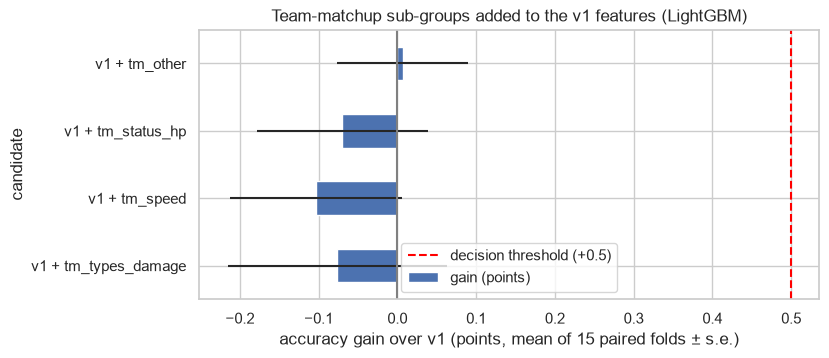

In [8]:
added = ablation[ablation["candidate"].str.startswith("v1 + ")].set_index("candidate")
ax = added["gain (points)"].plot.barh(xerr=added["std of gain"] / np.sqrt(len(REPEAT_SEEDS) * 5), figsize=(8, 3.5))
ax.axvline(0, c="grey")
ax.axvline(0.5, c="red", ls="--", label="decision threshold (+0.5)")
ax.set_xlabel("accuracy gain over v1 (points, mean of 15 paired folds ± s.e.)")
ax.set_title("Team-matchup sub-groups added to the v1 features (LightGBM)")
ax.legend()
plt.show()

## 5. Stress test on P2's KO recording

Same perturbation as experiment 04: in the validation folds a share of P2's Pokémon vanished with HP ≤ 0.5
become recorded KOs. The team-matchup features are built on the `lost_est`-style estimate, so in principle
they are unaffected; this checks that the model with v2 features is not more fragile than with v1.

Note: `perturb_p2_ko` changes only the v1 KO columns. On real data with more KOs recorded the new features
would not change either, because a vanished Pokémon with HP ≤ 0.5 is already treated as out of play.

In [9]:
t0 = time.time()
rows = {}
for name, cols in [("v1 all", NUM), ("v2 all", NUM2)]:
    st = stress_test(MODELS["lightgbm"], X_train[cols], y)
    rows[name] = {**st, "drop (points)": (st["clean"] - st["p2_ko_fixed_1"]) * 100}
print(f"done in {time.time() - t0:.0f}s")
pd.DataFrame(rows).T.round(4)

done in 36s


,clean,p2_ko_fixed_0.5,p2_ko_fixed_1,drop (points)
v1 all,0.6798,0.6794,0.6794,0.04
v2 all,0.6821,0.6808,0.6811,0.10


## 6. Which new features does the model use?

Gain importance of LightGBM fitted on the whole train set with v2 features (descriptive only: importances
are not used to select features).

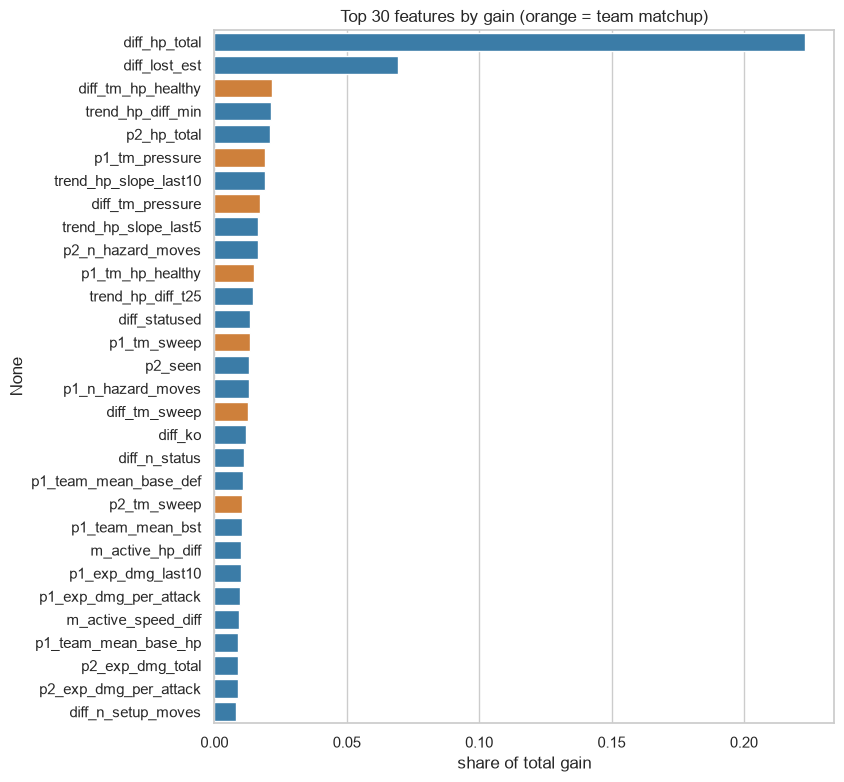

share of total gain in the team-matchup group: 18.0% (44 of 199 features)


In [10]:
full = MODELS["lightgbm"].fit(X_train[NUM2], y)
imp = pd.Series(full[-1].booster_.feature_importance(importance_type="gain"), index=NUM2)
imp = (imp / imp.sum()).sort_values(ascending=False)
top = imp.head(30)
plt.figure(figsize=(8, 9))
sns.barplot(x=top.values, y=top.index, hue=np.where(top.index.isin(TM), "team matchup", "v1"),
            palette={"team matchup": "#e67e22", "v1": "#2980b9"}, legend=False)
plt.title("Top 30 features by gain (orange = team matchup)")
plt.xlabel("share of total gain")
plt.show()
print(f"share of total gain in the team-matchup group: {imp[TM].sum():.1%} ({len(TM)} of {len(NUM2)} features)")

## 7. Saving the v2 features

Saved next to the v1 files without overwriting them (the submission notebooks of experiment 04 use v1).

In [11]:
X_train.assign(player_won=y).to_pickle(PROC / "features_train_v2.pkl")
X_test.to_pickle(PROC / "features_test_v2.pkl")
with open(PROC / "feature_groups_v2.json", "w") as f:
    json.dump({**groups, "team_matchup": TM, **SUB, "robust": ROBUST2}, f, indent=1)
for p in sorted(PROC.glob("feature*_v2*")):
    print(f"{p.name:26s} {p.stat().st_size / 1e6:6.1f} MB")

feature_groups_v2.json        0.0 MB
features_test_v2.pkl          8.2 MB
features_train_v2.pkl        16.4 MB


## 8. Summary

_To fill after the run._
- gain of v2 over v1 with LightGBM and LogReg, all features and robust subset (section 4);
- which sub-groups help (section 4.1) and which new features the model uses (section 6);
- stress test (section 5);
- decision with the rule fixed above: keep the group (and re-tune / rebuild the submissions) only if the gain
  is above ~0.5 points; otherwise freeze the v1 features.